# Data loading and cleaning

## 1. Basic examination

In [1]:
import pandas as pd

df = pd.read_csv("Instagram_Analytics.csv")

print("Shape:")
print(df.shape)

Shape:
(29999, 23)


In [3]:
print("\nFirst 5 rows:")
print(df.head())


First 5 rows:
     post_id  account_id account_type  follower_count media_type  \
0  IG0000001           7        brand            3551       reel   
1  IG0000002          20      creator           31095      image   
2  IG0000003          15        brand            8167       reel   
3  IG0000004          11      creator            9044   carousel   
4  IG0000005           8      creator           15986       reel   

  content_category traffic_source  has_call_to_action        post_datetime  \
0       Technology      Home Feed                   1  2024-11-30 06:00:00   
1          Fitness       Hashtags                   1  2025-08-15 15:00:00   
2           Beauty     Reels Feed                   0  2025-09-11 16:00:00   
3            Music       External                   0  2025-09-18 03:00:00   
4       Technology        Profile                   0  2025-03-21 09:00:00   

    post_date  ...  comments shares  saves  reach  impressions  \
0  2024-11-30  ...         5      7     3

In [4]:
print("\nData types:")
print(df.dtypes)


Data types:
post_id                      object
account_id                    int64
account_type                 object
follower_count                int64
media_type                   object
content_category             object
traffic_source               object
has_call_to_action            int64
post_datetime                object
post_date                    object
post_hour                     int64
day_of_week                  object
likes                         int64
comments                      int64
shares                        int64
saves                         int64
reach                         int64
impressions                   int64
engagement_rate             float64
followers_gained              int64
caption_length                int64
hashtags_count                int64
performance_bucket_label     object
dtype: object


In [5]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
post_id                     0
account_id                  0
account_type                0
follower_count              0
media_type                  0
content_category            0
traffic_source              0
has_call_to_action          0
post_datetime               0
post_date                   0
post_hour                   0
day_of_week                 0
likes                       0
comments                    0
shares                      0
saves                       0
reach                       0
impressions                 0
engagement_rate             0
followers_gained            0
caption_length              0
hashtags_count              0
performance_bucket_label    0
dtype: int64


In [6]:
print("\nDuplicate rows:")
print(df.duplicated().sum())
print("\nDuplicate post_id:")
print(df["post_id"].duplicated().sum())


Duplicate rows:
0

Duplicate post_id:
0


## Change data type 

In [2]:
import pandas as pd

# 保留原始資料
clean_df = df.copy()

# 1. account_id:
# 數字只是帳號識別碼，不具有大小或距離意義
clean_df["account_id"] = clean_df["account_id"].astype("category")

# 2. has_call_to_action:
# 0 / 1 → False / True
clean_df["has_call_to_action"] = clean_df["has_call_to_action"].astype(bool)

# 3. post_datetime:
# 轉成日期＋時間格式
clean_df["post_datetime"] = pd.to_datetime(
    clean_df["post_datetime"],
    errors="coerce"
)

# 4. post_date:
# 轉成日期格式
clean_df["post_date"] = pd.to_datetime(
    clean_df["post_date"],
    errors="coerce"
)

# 檢查修改後的資料型態
print(clean_df[
    [
        "account_id",
        "has_call_to_action",
        "post_datetime",
        "post_date"
    ]
].dtypes)

# 儲存成新的資料集
clean_df.to_csv(
    "instagram_analytics_cleaned.csv",
    index=False
)

print("Cleaned dataset saved.")

account_id                  category
has_call_to_action              bool
post_datetime         datetime64[ns]
post_date             datetime64[ns]
dtype: object
Cleaned dataset saved.


## 2. Descriptive statistics

In [3]:
# Numerical descriptive statistics
numeric_data = clean_df.select_dtypes(
    include="number"
)

print(numeric_data.describe())

       follower_count     post_hour         likes      comments        shares  \
count    29999.000000  29999.000000  29999.000000  29999.000000  29999.000000   
mean     10278.305477     11.499417    287.653588      8.521917     14.426614   
std       6691.862669      6.900587    317.647682     10.116505     16.420899   
min       3083.000000      0.000000      0.000000      0.000000      0.000000   
25%       5824.000000      6.000000    104.000000      3.000000      5.000000   
50%       9044.000000     12.000000    199.000000      6.000000     10.000000   
75%      10739.000000     17.000000    363.000000     11.000000     19.000000   
max      31095.000000     23.000000  10632.000000    339.000000    516.000000   

              saves         reach    impressions  engagement_rate  \
count  29999.000000  29999.000000   29999.000000     29999.000000   
mean      42.517284   6272.475449    8466.952498         0.042107   
std       47.808844   4985.877059    6825.900355         0.0240

In [4]:
# =========================
# Categorical descriptive statistics
# =========================

categorical_columns = [
    "account_id",
    "account_type",
    "media_type",
    "content_category",
    "traffic_source",
    "has_call_to_action",
    "day_of_week",
    "performance_bucket_label"
]

print(
    clean_df[categorical_columns].describe()
)

        account_id account_type media_type content_category traffic_source  \
count        29999        29999      29999            29999          29999   
unique          20            2          3               10              6   
top             13      creator      image      Photography      Home Feed   
freq          1599        20944      11927             3035           5069   

       has_call_to_action day_of_week performance_bucket_label  
count               29999       29999                    29999  
unique                  2           7                        4  
top                 False    Thursday                    viral  
freq                19536        4351                     7500  


In [5]:
# =========================
# Date descriptive statistics
# =========================

print("First post date:")
print(clean_df["post_date"].min())

print("Last post date:")
print(clean_df["post_date"].max())

print("Time span:")
print(
    clean_df["post_date"].max()
    - clean_df["post_date"].min()
)

First post date:
2024-11-19 00:00:00
Last post date:
2025-11-19 00:00:00
Time span:
365 days 00:00:00


### Visualize

In [23]:
%pip install kaleido

In [12]:
%pip install --upgrade "plotly>=6.1"

Note: you may need to restart the kernel to use updated packages.
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)
   ---------------------------------------- 0.0/490.6 kB ? eta -:--:--
   ---------------------------------------- 0.0/490.6 kB ? eta -:--:--
    --------------------------------------- 10.2/490.6 kB ? eta -:--:--
   -- ------------------------------------ 30.7/490.6 kB 325.1 kB/s eta 0:00:02
   --- ----------------------------------- 41.0/490.6 kB 279.3 kB/s eta 0:00:02
   --- ----------------------------------- 41.0/490.6 kB 279.3 kB/s eta 0:00:02
   --- ----------------------------------- 41.0/490.6 kB 279.3 kB/s eta 0:00:02
   --- ----------------------------------- 41.0/490.6 kB 279.3 kB/s eta 0:00:02
   ------- ------------------------------- 92.2/490.6 kB 308.0 kB/s eta 0:00:02
   ------------- ------------------------ 174.1/490.6 kB 476.3 kB/s eta 0:00:01
   ------------- ------------------------ 174

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


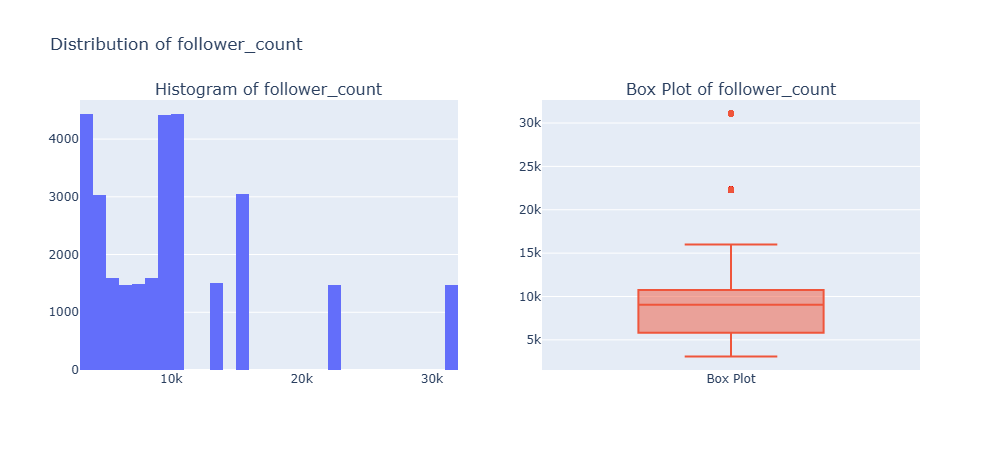

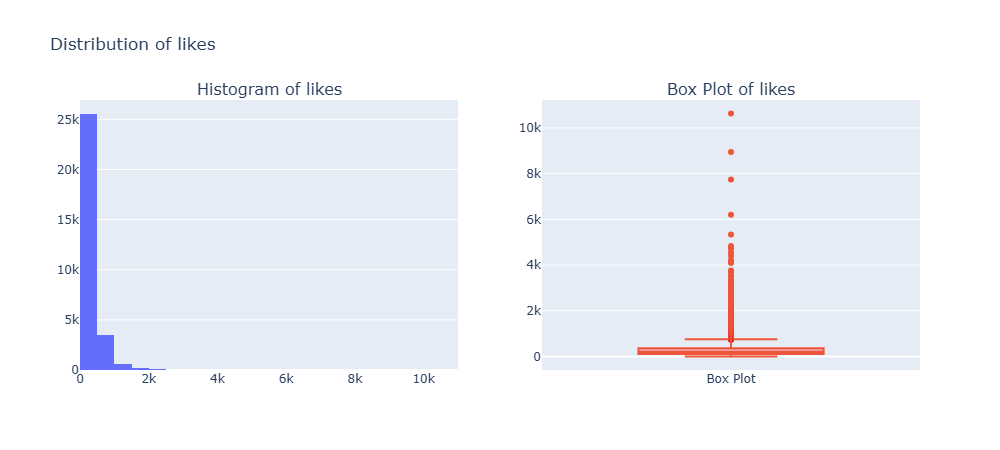

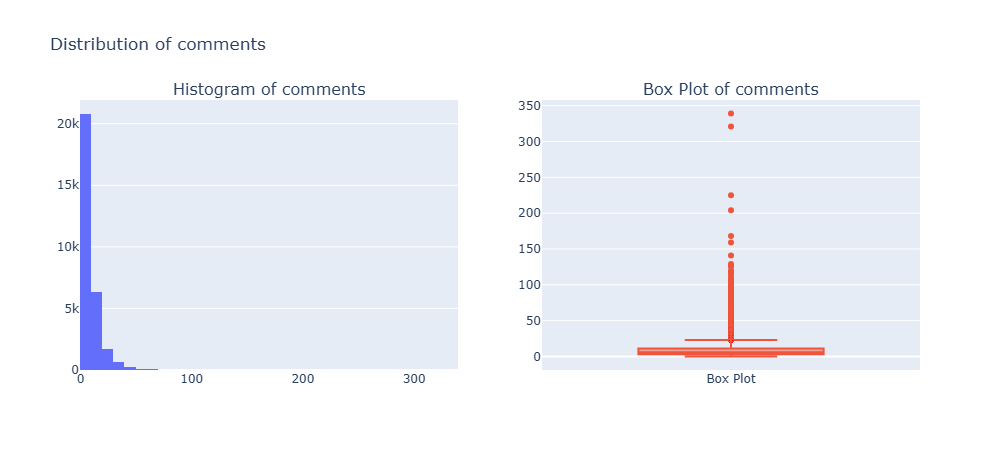

c:\Users\peggy\anaconda3\Lib\site-packages\choreographer\utils\_tmpfile.py:138: TmpDirWarning: The temporary directory could not be deleted, execution will continue. errors: [(WindowsPath('C:/Users/peggy/AppData/Local/Temp/tmpy3npwd8f/CrashpadMetrics-active.pma'), PermissionError(13, '存取被拒。')), (WindowsPath('C:/Users/peggy/AppData/Local/Temp/tmpy3npwd8f'), OSError(41, '目錄不是空的。'))]
  warnings.warn(  # noqa: B028
Temporary dictory couldn't be removed manually.


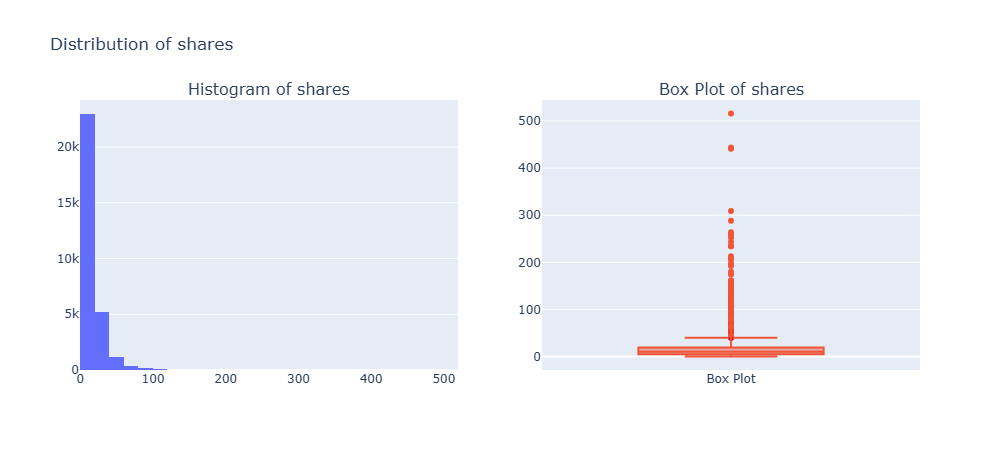

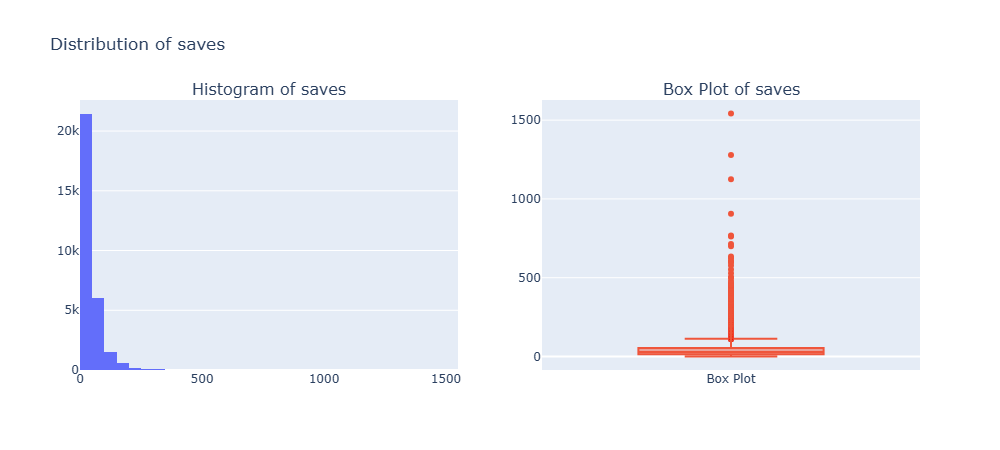

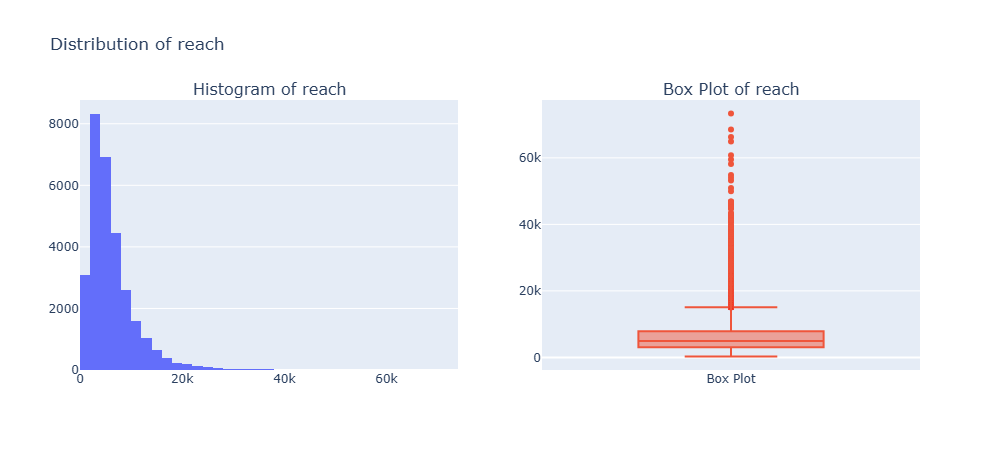

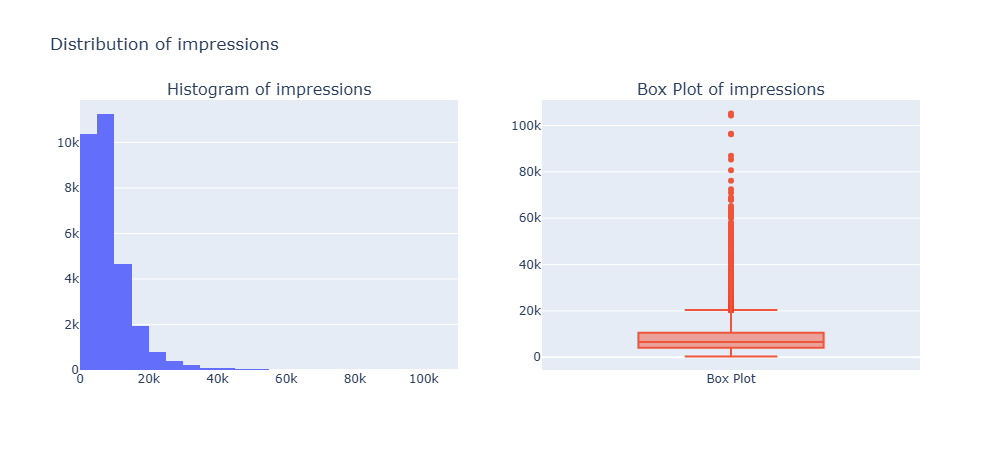

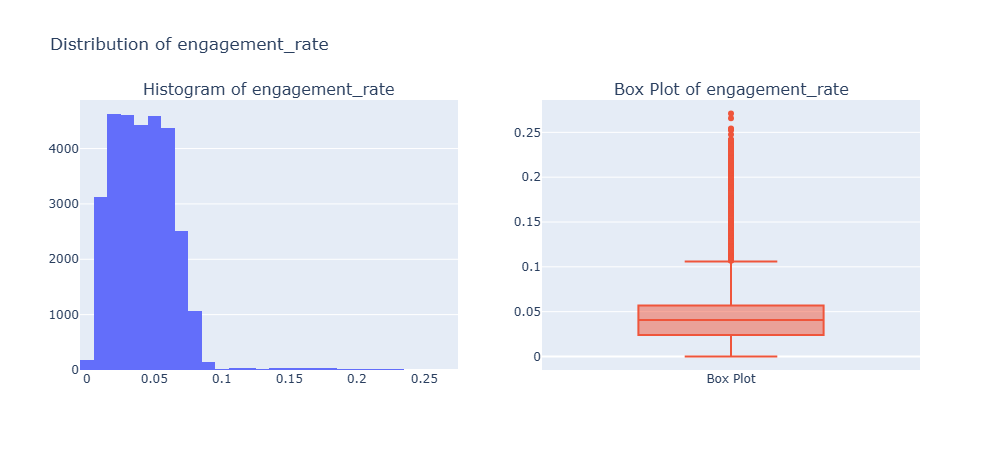

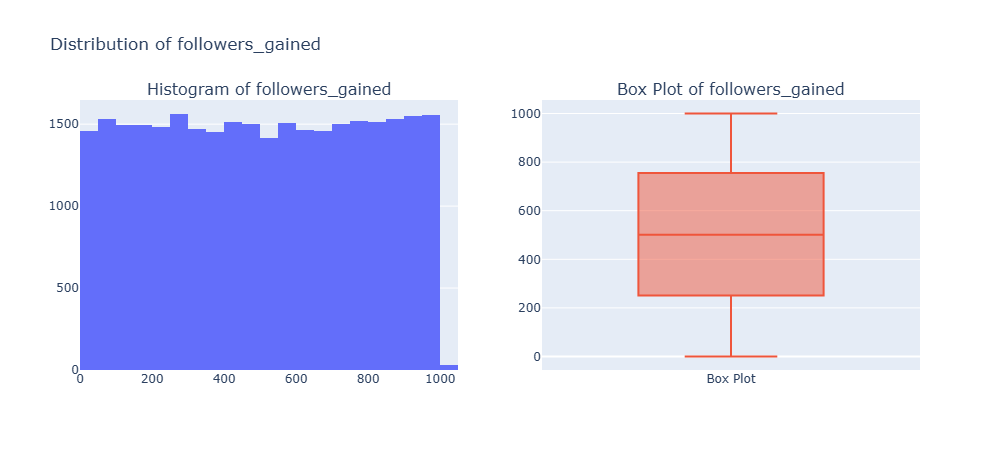

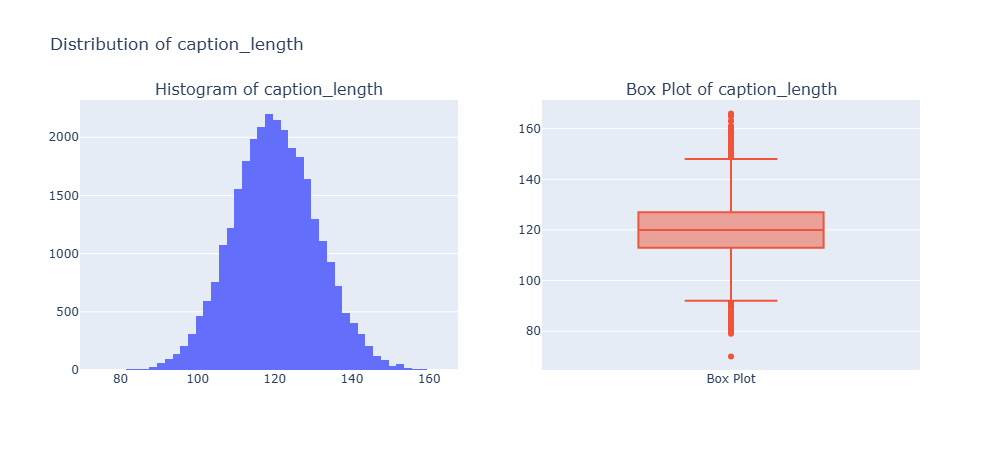

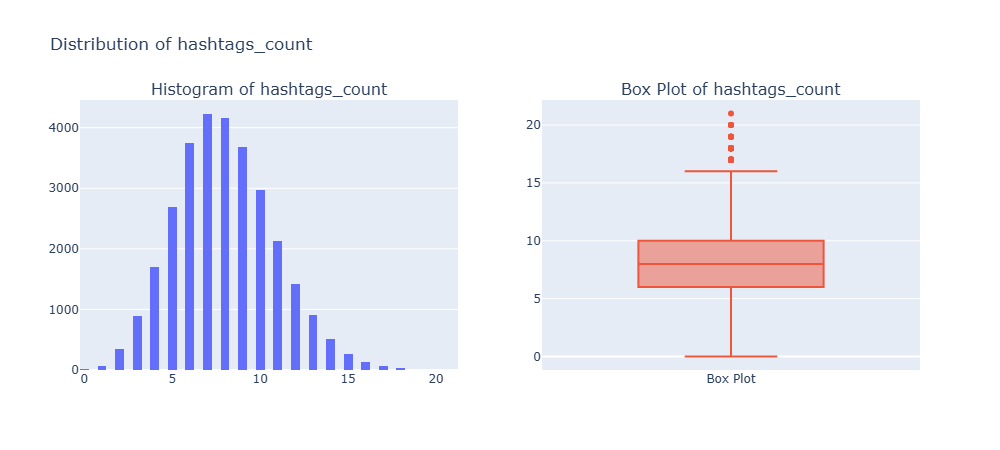

In [6]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

continuous_columns = [
    "follower_count",
    "likes",
    "comments",
    "shares",
    "saves",
    "reach",
    "impressions",
    "engagement_rate",
    "followers_gained",
    "caption_length",
    "hashtags_count"
]

for col in continuous_columns:

    data = clean_df[col].dropna()

    fig = make_subplots(
        rows=1,
        cols=2,
        subplot_titles=(
            f"Histogram of {col}",
            f"Box Plot of {col}"
        )
    )

    # Histogram
    fig.add_trace(
        go.Histogram(
            x=data,
            nbinsx=50,
            name="Histogram"
        ),
        row=1,
        col=1
    )

    # Box plot
    fig.add_trace(
        go.Box(
            y=data,
            name="Box Plot",
            boxpoints="outliers"
        ),
        row=1,
        col=2
    )

    fig.update_layout(
        title_text=f"Distribution of {col}",
        showlegend=False,
        height=450,
        width=1000
    )

    # Use static image so GitHub can display it
    fig.show(renderer="png")

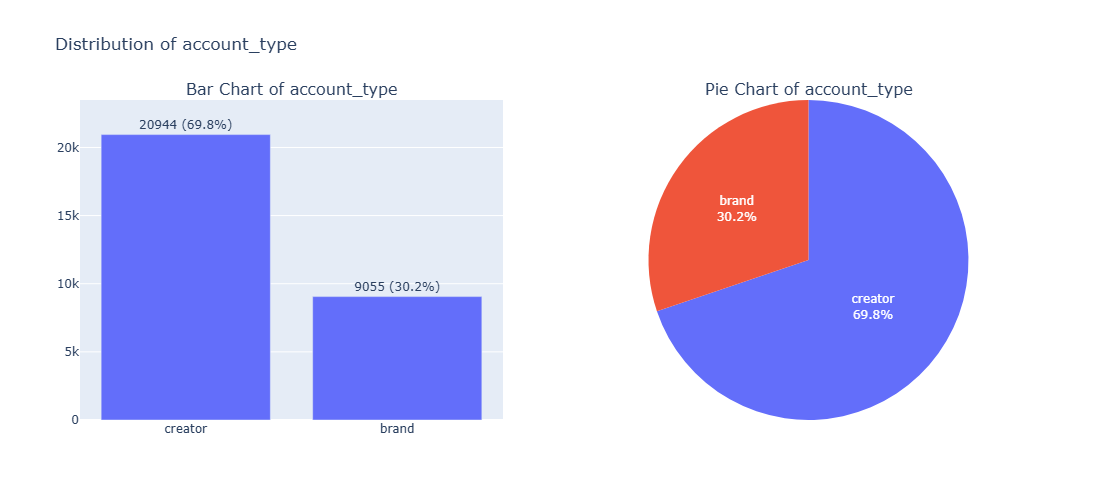

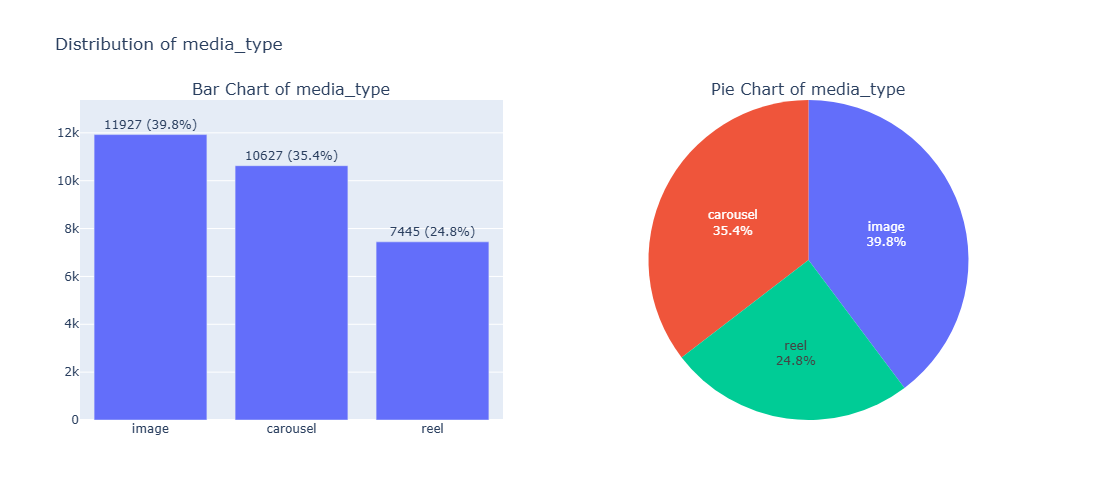

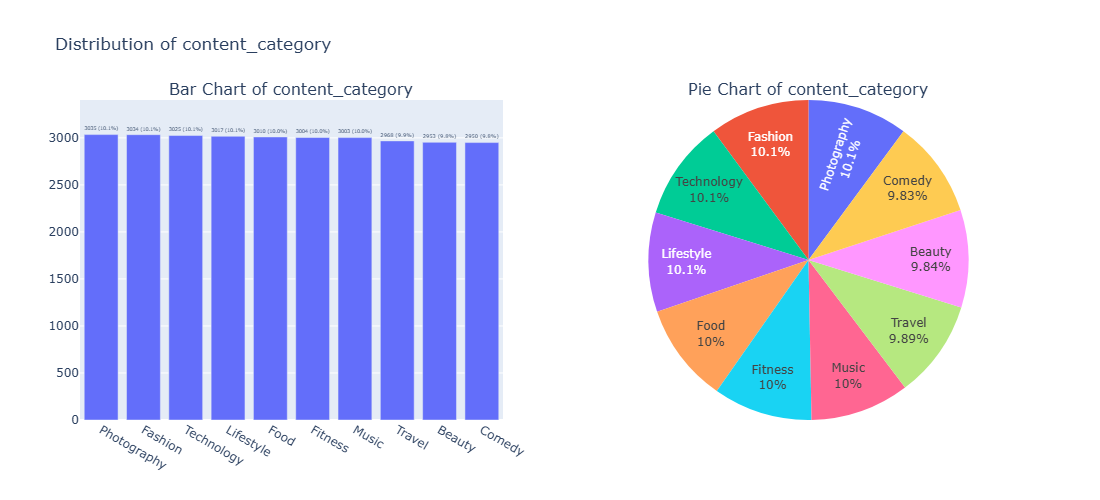

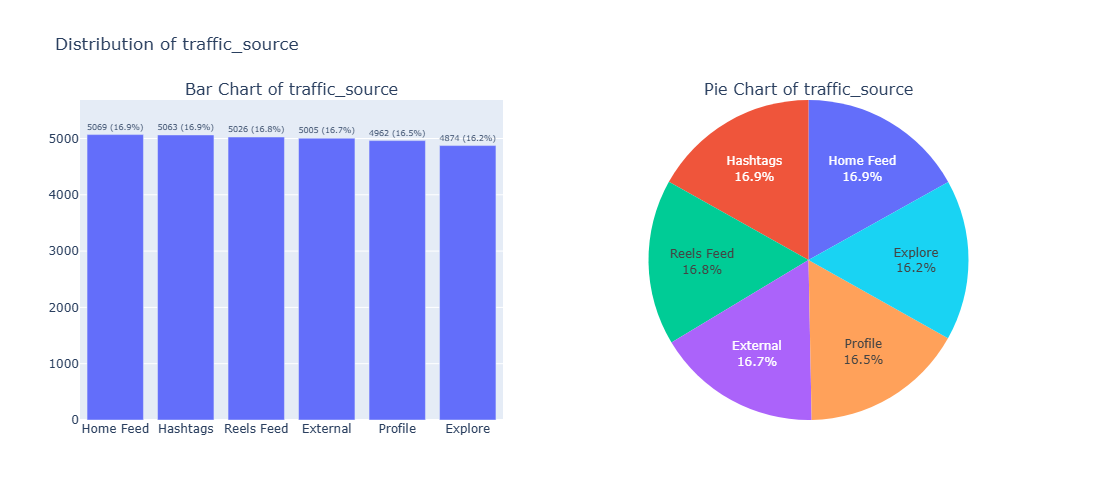

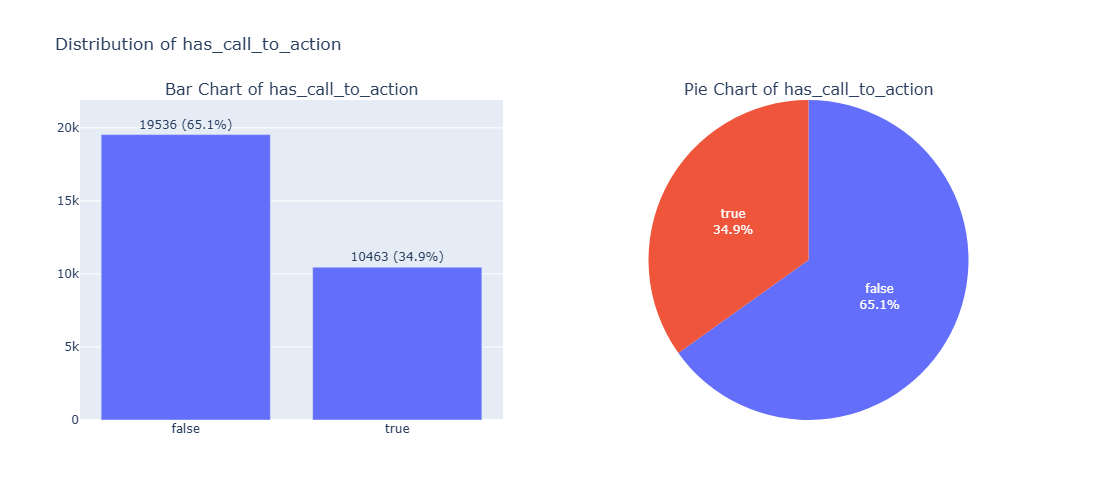

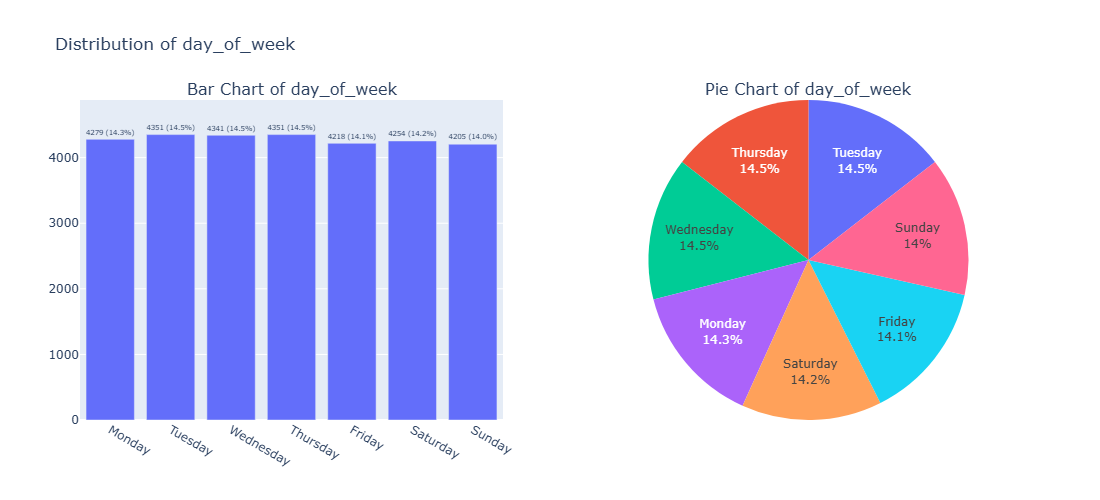

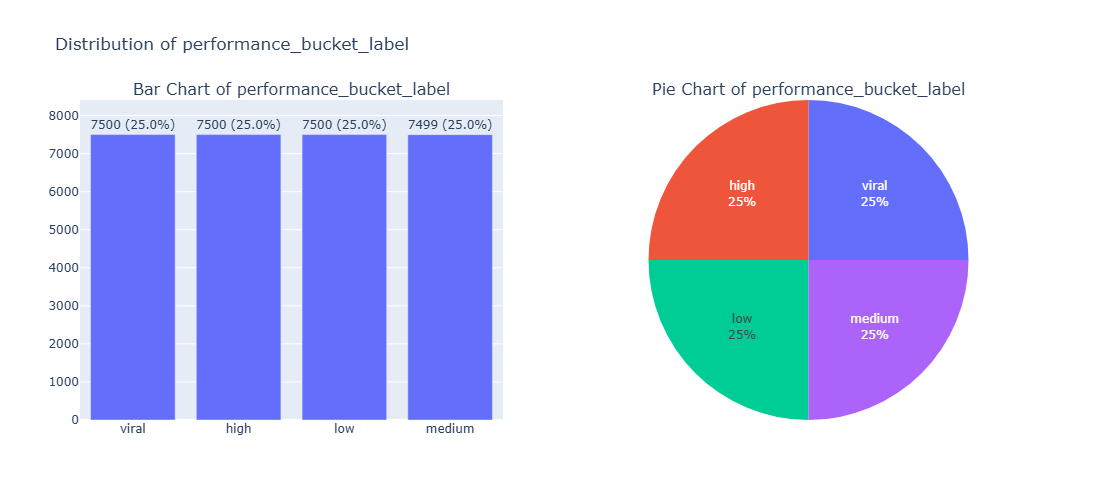

In [7]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

categorical_columns = [
    "account_type",
    "media_type",
    "content_category",
    "traffic_source",
    "has_call_to_action",
    "day_of_week",
    "performance_bucket_label"
]

for col in categorical_columns:

    # Prepare count and percentage
    count_data = (
        clean_df[col]
        .value_counts(dropna=False)
        .reset_index()
    )

    count_data.columns = [
        col,
        "count"
    ]

    count_data["percentage"] = (
        count_data["count"]
        / count_data["count"].sum()
        * 100
    )

    count_data["label"] = (
        count_data["count"].astype(str)
        + " ("
        + count_data["percentage"].round(1).astype(str)
        + "%)"
    )

    # Keep day of week in chronological order
    if col == "day_of_week":

        day_order = [
            "Monday",
            "Tuesday",
            "Wednesday",
            "Thursday",
            "Friday",
            "Saturday",
            "Sunday"
        ]

        count_data[col] = pd.Categorical(
            count_data[col],
            categories=day_order,
            ordered=True
        )

        count_data = count_data.sort_values(col)

    # Create bar chart + pie chart
    fig = make_subplots(
        rows=1,
        cols=2,
        specs=[
            [
                {"type": "xy"},
                {"type": "domain"}
            ]
        ],
        subplot_titles=(
            f"Bar Chart of {col}",
            f"Pie Chart of {col}"
        )
    )

    # Bar chart
    fig.add_trace(
        go.Bar(
            x=count_data[col],
            y=count_data["count"],
            text=count_data["label"],
            textposition="outside",
            name="Count"
        ),
        row=1,
        col=1
    )

    # Pie chart
    fig.add_trace(
        go.Pie(
            labels=count_data[col],
            values=count_data["count"],
            textinfo="label+percent"
        ),
        row=1,
        col=2
    )

    fig.update_layout(
        title_text=f"Distribution of {col}",
        showlegend=False,
        height=500,
        width=1100
    )

    # Use static image so GitHub can display it
    fig.show(renderer="png")